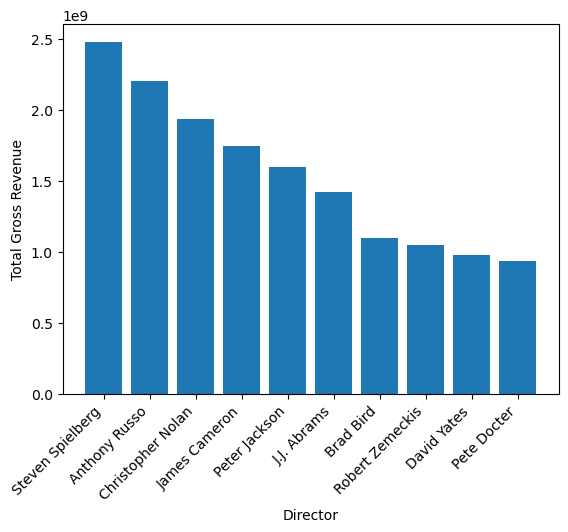

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("imdb_top_1000.csv")

# Data wrangling
data["Gross"] = data["Gross"].str.replace(',', '') # data cleaning: replaced all commas with empty strings to convert to numbers
data["Gross"] = pd.to_numeric(data['Gross'], errors = 'coerce') # convert the strings to numbers, errors = coerce converts the non-numbers to NaN
gross_by_director = data.groupby('Director').agg({'Gross': 'sum', 'Director': 'count'}) #makes a separate table of directors by their total revenue and movie count
gross_by_director.columns = ['Gross', 'Movies'] # renames the columns to gross and movies
gross_by_director = gross_by_director[gross_by_director['Movies'] >= 3] # removes directors with less than 3 movies made

sorted_gross = gross_by_director.sort_values(by = "Gross", ascending = False) #sorts the table by gross in descending order
top10 = sorted_gross.head(10) # gets the top 10

# Plotting
plt.bar(top10.index, top10["Gross"]) # makes a bar graph
plt.xticks(rotation=45, ha='right') # rotates director names for readability
plt.xlabel('Director') # labels the axis by director
plt.ylabel('Total Gross Revenue') #labels the y axis by gross revenue
plt.show()